# -------MNIST----------

In [98]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [99]:
data_path = os.path.expanduser('~/MNIST')

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root=data_path,
    train=False,
    download=True,
    transform=transform

)

image, label = train_dataset[0]
print(len(train_dataset), image.shape, label)
print(len(test_dataset))




60000 torch.Size([1, 28, 28]) 5
10000


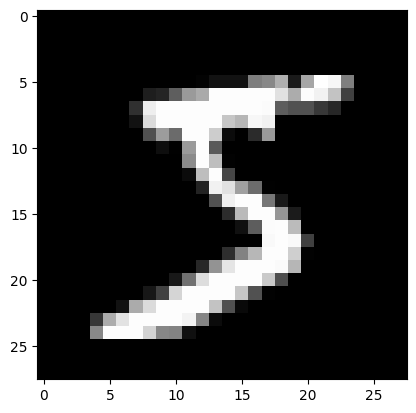

In [100]:
plt.imshow(image.squeeze(), cmap='gray')
plt.show()

In [101]:
loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
images, labels = next(iter(loader))
print(images.shape, labels.shape)

torch.Size([32, 1, 28, 28]) torch.Size([32])


In [102]:
flat_images = images.flatten(start_dim=1)
print(flat_images.shape)

torch.Size([32, 784])


In [103]:
layer = torch.nn.Linear(784, 10) #Create randomized weights. 
scores = layer(flat_images)
print(scores.shape)

torch.Size([32, 10])


In [104]:
print(layer.weight.shape)
print(layer.bias.shape)
print(layer.weight[0, :10])

torch.Size([10, 784])
torch.Size([10])
tensor([-0.0140,  0.0262, -0.0267,  0.0236,  0.0134, -0.0199, -0.0212,  0.0315,
        -0.0278, -0.0165], grad_fn=<SliceBackward0>)


In [105]:
predictions = scores.argmax(dim=1)
print('Guess: ', predictions[1].item())
print('Correct: ', labels[1].item())

Guess:  8
Correct:  6


In [106]:
predictions = scores.argmax(dim=1)
accuracy = (predictions == labels).float().mean()

print(accuracy.item())

0.09375


### Go through one epoch

In [107]:

loss_fn = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(layer.parameters(), lr = 0.01)

def train_model():
    layer.train()

    for batch_num, (images, labels) in enumerate(loader):
        flat_images = images.flatten(start_dim=1)
        scores = layer(flat_images)
        loss = loss_fn(scores, labels)

        optimizer.zero_grad() # Clean of old gradiens, for a new batch. 
        loss.backward() # Backwards prop to get gradient    
        optimizer.step() # Update weights with


In [108]:
predictions = scores.argmax(dim=1) ## Last batch to see accuracy. 
accuracy = (predictions == labels).float().mean()

print(accuracy.item())

0.09375


### Test data

In [109]:
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False) # Creates a loader that batches 10k pics into batches of 32. 

In [110]:


def evaluate_model():
    layer.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            flat_images = images.flatten(start_dim=1)
            scores = layer(flat_images)
            predictions = scores.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total   += labels.size(0)
    accuracy = correct/total
    return accuracy

In [111]:
results = []

epochs = 10
for i in range(epochs):
    train_model()
    accuracy = evaluate_model()
    results.append(accuracy)

results_df = pd.DataFrame({
    'epoch':np.arange(1,epochs + 1),
    'accuracy':results
})

results_df

,epoch,accuracy
0,1,0.8858
1,2,0.8962
2,3,0.9033
3,4,0.9063
4,5,0.9104
5,6,0.9105
6,7,0.9134
7,8,0.9152
8,9,0.9159
9,10,0.9165


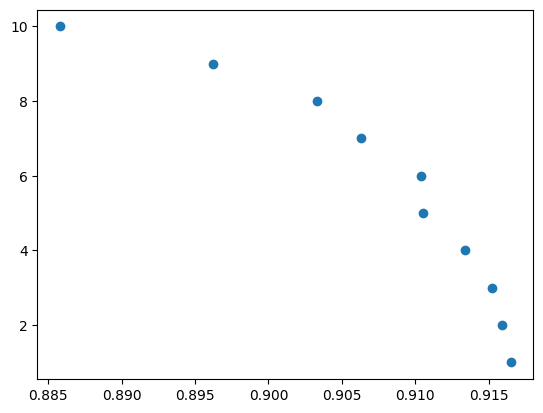

In [ ]:

plt.scatter(
    x = results_df['accuracy'],
    y=results_df['epoch'].sort_values(ascending=True)
    )